In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os, sys
from termcolor import cprint
HERE = 'c:\\Users\\harry\\Documents\\code_ws\\pb_ws\\coop_assembly\\src\\coop_assembly\\planning\\'
pyplanner_path = os.path.abspath(os.path.join(HERE, '..', '..', '..', 'external', 'pyplanners'))
sys.path.extend([
    os.path.abspath(os.path.join(HERE, '..', '..', '..', 'external', 'pddlstream')),
    pyplanner_path,
])
os.environ['PYPLANNERS_PATH'] = pyplanner_path

import pddlstream
cprint("Using pddlstream from {}".format(pddlstream.__file__), 'yellow')
import strips # pyplanners
cprint("Using strips from {}".format(strips.__file__), 'yellow')

Using pddlstream from c:\Users\harry\Documents\code_ws\pb_ws\coop_assembly\external\pddlstream\pddlstream\__init__.py
Using strips from c:\Users\harry\Documents\code_ws\pb_ws\coop_assembly\external\pyplanners\strips\__init__.py


In [3]:
import numpy as np
np.set_printoptions(precision=3)

## Load shapes

In [4]:
test_file_name = 'SP_arch.json' # | SP_arch | 1_exp_tets

In [154]:
from coop_assembly.data_structure import BarStructure
from coop_assembly.planning.parsing import get_assembly_path, load_structure
from coop_assembly.help_functions.parsing import parse_saved_structure_data
from coop_assembly.help_functions.shared_const import METER_SCALE
from coop_assembly.planning.parsing import unpack_structure
from coop_assembly.planning.visualization import set_camera

import pybullet_planning as pp

connect_pb = True
viewer = True
bar_struct, o_struct = load_structure(test_file_name, connect_pb=connect_pb, viewer=viewer)
if connect_pb:
    pp.create_plane(color=pp.WHITE)
    pp.draw_pose(pp.unit_pose())

# transform model
new_world_from_base = pp.Pose(point=(np.array([0,0,0])))
world_from_base = pp.Pose(point=bar_struct.base_centroid(METER_SCALE))
# rotation = Pose(euler=Euler(roll=BASE_ROLL, pitch=BASE_PITCH, yaw=BASE_YAW))
rotation = pp.unit_pose()
tf = pp.multiply(new_world_from_base, rotation, pp.invert(world_from_base))
bar_struct.transform(tf, scale=METER_SCALE)
bar_struct.generate_grounded_connection();

element_from_index, grounded_elements, contact_from_connectors, connectors = \
    unpack_structure(bar_struct, chosen_bars=None, scale=METER_SCALE, color=pp.apply_alpha(pp.RED, 0.1))
if connect_pb:
    set_camera([bar_struct.base_centroid(METER_SCALE)], camera_dist=1.25, scale=1.)

all_elements = list(element_from_index.keys())

Parsed file name: c:\users\harry\documents\code_ws\pb_ws\coop_assembly\tests\test_data\SP_arch.json | write_time: 2020-12-30 12:10:48.047718 | 


In [155]:
print(bar_struct.base_centroid(METER_SCALE))

[ 0. -0.  0.]


## Check scaffolds work with conmech

In [164]:
from stiffness import conmech_model_from_bar_structure, create_stiffness_checker, evaluate_stiffness, draw_conmech_model

# model, fem_element_from_bar_id = conmech_model_from_bar_structure(bar_struct)
checker, fem_element_from_bar_id = create_stiffness_checker(bar_struct, presample_scaffolds=True)
            
if connect_pb:
    draw_conmech_model(checker.model, fem_element_from_bar_id, elements=None);

In [165]:
from collections import defaultdict

elem_ind_from_elem_tag = checker._sc_ins.get_elem_ind_from_elem_tag()
scaffold_elements = elem_ind_from_elem_tag['scaffold']

cm_nodes_from_bar_id = defaultdict(set)
for bar_id, fem_es in fem_element_from_bar_id.items():
    for fem_e_id in fem_es:
        fem_element = checker.model.elements[fem_e_id]
        cm_nodes_from_bar_id[bar_id].update(fem_element.end_node_inds)
        
bar_id_from_scaffolds = defaultdict(set)
for se_id in scaffold_elements:
    se_element = checker.model.elements[se_id]
    for bar_id, cm_node_ids in cm_nodes_from_bar_id.items():
        for cm_node_id in list(cm_node_ids):
            if cm_node_id in se_element.end_node_inds:
                if bar_id != -1:
                    bar_id_from_scaffolds[se_id].add(bar_id)

In [166]:
all_scaffolds = set(bar_id_from_scaffolds)

In [167]:
len(scaffold_elements)

77

In [168]:
pp.remove_all_debug()

In [10]:
seq = [36, 1, 0, 2, 37, 35, 38, 32, 30, 31, 7, 6, 25, 3, 4, 5, 33, 9, 27, 26, 8, 12, 20, 23, 17, 34, 29, 11, 24, 10, 21, 22, 16, 28, 14, 19, 13, 15, 18]

### Before adding the scaffold element

In [11]:
partial_elements = [seq[i] for i in range(22)]

deformation_result = evaluate_stiffness(bar_struct, partial_elements, checker=checker,
    fem_element_from_bar_id=fem_element_from_bar_id, verbose=True)

if connect_pb:
    draw_conmech_model(checker.model, fem_element_from_bar_id, elements=partial_elements);

Stiff: True | Compliance: 0.00001
Max translation deformation: 0.00352 / 0.005 = 0.70393, at node #110


In [12]:
pp.remove_all_debug()

### After adding the scaffold element

In [13]:
partial_elements = [seq[i] for i in range(22)] + [350]
print(partial_elements)

deformation_result = evaluate_stiffness(bar_struct, partial_elements, checker=checker,
    fem_element_from_bar_id=fem_element_from_bar_id, verbose=True)

if connect_pb:
    draw_conmech_model(checker.model, fem_element_from_bar_id, elements=partial_elements);

[36, 1, 0, 2, 37, 35, 38, 32, 30, 31, 7, 6, 25, 3, 4, 5, 33, 9, 27, 26, 8, 12, 350]
Stiff: True | Compliance: 0.00000
Max translation deformation: 0.00063 / 0.005 = 0.12567, at node #119


In [14]:
pp.remove_all_debug()

## Define stream functions

In [93]:
from coop_assembly.planning.utils import compute_z_distance, check_connected, Command
from coop_assembly.planning.stiffness import test_stiffness

def get_wild_remove_element_gen_fn(bar_struct, element_from_index, grounded_elements, connectors, debug=False, use_fluent=True, \
    connectivity=True, stiffness=True, checker_info=(None,None), verbose=False):
    def wild_gen_fn(robot_name, element, fluents=[]):
        next_printed = set()
        for fact in fluents:
            if fact[0] == 'assembled':
                #if fact[1] != element:
                next_printed.add(fact[1])
            else:
                raise NotImplementedError(fact[0])

        assert element in next_printed
        next_printed = next_printed - {element}
        if verbose:
            print('---')
            print('Remove E{} - fluent printed ({}): {}'.format(element, len(next_printed), sorted(next_printed)))

        # # * partial ordering
        # if ordering and (outgoing_from_element[element] & next_printed):
        #     # outgoing elements must be removed BEFORE element
        #     cprint('Ordering fails.', 'red')
        #     return

        # * connectivity
        if connectivity and not check_connected(connectors, grounded_elements, next_printed):
            if verbose: cprint('Connectivity fails.', 'red')
            return

        if stiffness and not test_stiffness(bar_struct, next_printed, checker=checker_info[0],
            fem_element_from_bar_id=checker_info[1], verbose=verbose):
            if verbose: cprint('Stiffness fails.', 'red')
            return

        if debug:
            num_outputs = 2 if use_fluent else 3
            outputs = [num_outputs*(None,)]
            yield outputs # For debugging
            return
        
        command = Command([])
        grasp = None
        outputs = [(command, grasp)]
        yield outputs
    # end wild_gen_fn
    return wild_gen_fn

In [143]:
def get_wild_add_element_gen_fn(bar_struct, element_from_index, grounded_elements, connectors, debug=False,
    use_fluent=True, connectivity=True, stiffness=True, allow_scaffolds=False, checker_info=(None,None), verbose=False):
    all_elements = set(element_from_index)
    def wild_gen_fn(robot_name, element, fluents=[]):
        next_printed = set()
        scaffold_printed = set()
        for fact in fluents:
            if fact[0] == 'assembled':
                next_printed.add(fact[1])
            else:
                raise NotImplementedError(fact[0])                

        assert element not in next_printed
        next_printed = next_printed | {element}
        if verbose:
            print('---')
            print('Add E{} - fluent printed ({}): {}'.format(element, len(next_printed), sorted(next_printed)))

        # # * partial ordering
        # if ordering and (outgoing_from_element[element] & next_printed):
        #     # outgoing elements must be removed BEFORE element
        #     cprint('Ordering fails.', 'red')
        #     return

        # * connectivity, only for original structure for now
        if connectivity and not check_connected(connectors, grounded_elements, next_printed & all_elements):
            if verbose: cprint('Connectivity fails.', 'red')
            return

        if stiffness and not test_stiffness(bar_struct, next_printed, checker=checker_info[0],
            fem_element_from_bar_id=checker_info[1], verbose=verbose):
            if verbose: cprint('Stiffness fails.', 'red')
            return

        if debug:
            num_outputs = 2 if use_fluent else 3
            outputs = [num_outputs*(None,)]
            yield outputs # For debugging
            return
        
        command = Command([])
        grasp = None
        outputs = [(command, grasp)]
        yield outputs
    # end wild_gen_fn
    return wild_gen_fn

In [179]:
def get_wild_add_scaffold_element_gen_fn(bar_struct, element_from_index, grounded_elements, bar_id_from_scaffolds, debug=False,
    use_fluent=True, connectivity=True, stiffness=True, checker_info=(None,None), verbose=False):
    def wild_gen_fn(robot_name, scaffold_element, fluents=[]):
        next_printed = set()
        for fact in fluents:
            if fact[0] == 'assembled':
                next_printed.add(fact[1])
            else:
                raise NotImplementedError(fact[0])

        if verbose:
            print('---')
            print('Add Scaffold E{} - fluent printed ({}): {}'.format(scaffold_element, len(next_printed), sorted(next_printed)))

        # # * partial ordering
        # if ordering and (outgoing_from_element[element] & next_printed):
        #     # outgoing elements must be removed BEFORE element
        #     cprint('Ordering fails.', 'red')
        #     return

        # * connectivity
        if connectivity and not (bar_id_from_scaffolds[scaffold_element] & next_printed):
            if verbose: cprint('Scaffold connectivity fails.', 'red')
            return

        next_printed = next_printed | {scaffold_element}
        if stiffness and not test_stiffness(bar_struct, next_printed, checker=checker_info[0],
            fem_element_from_bar_id=checker_info[1], verbose=verbose):
            if verbose: cprint('Scaffold stiffness fails.', 'red')
            return

        if debug:
            num_outputs = 2 if use_fluent else 3
            outputs = [num_outputs*(None,)]
            yield outputs # For debugging
            return
        
        command = Command([])
        grasp = None
        outputs = [(command, grasp)]
        yield outputs
    # end wild_gen_fn
    return wild_gen_fn

## Construct PDDL problem

In [175]:
printed=set()
removed=set()
debug = False

# constraint
stiffness = True
forward = True
allow_scaffold = True
costs = False
verbose = False

trans_tol = 0.0005

In [176]:
from stiffness import conmech_model_from_bar_structure, create_stiffness_checker, evaluate_stiffness, draw_conmech_model

checker, fem_element_from_bar_id = create_stiffness_checker(bar_struct, presample_scaffolds=True, trans_tol=trans_tol)
            
# if connect_pb:
#     draw_conmech_model(checker.model, fem_element_from_bar_id, elements=None);

from collections import defaultdict

elem_ind_from_elem_tag = checker._sc_ins.get_elem_ind_from_elem_tag()
scaffold_elements = elem_ind_from_elem_tag['scaffold']

cm_nodes_from_bar_id = defaultdict(set)
for bar_id, fem_es in fem_element_from_bar_id.items():
    for fem_e_id in fem_es:
        fem_element = checker.model.elements[fem_e_id]
        cm_nodes_from_bar_id[bar_id].update(fem_element.end_node_inds)
        
bar_id_from_scaffolds = defaultdict(set)
for se_id in scaffold_elements:
    se_element = checker.model.elements[se_id]
    for bar_id, cm_node_ids in cm_nodes_from_bar_id.items():
        for cm_node_id in list(cm_node_ids):
            if cm_node_id in se_element.end_node_inds:
                if bar_id != -1:
                    bar_id_from_scaffolds[se_id].add(bar_id)

all_scaffolds = set(bar_id_from_scaffolds)

In [180]:
from pddlstream.utils import read
from pddlstream.language.stream import StreamInfo, PartialInputs, WildOutput, DEBUG
from pddlstream.language.constants import And, PDDLProblem, Equal, print_plan

formu = 'forward' if forward else 'backward'
if allow_scaffold:
    formu += '_scaffold'
domain_pddl = read(os.path.join(HERE, 'pddl/stiffness/domain_{}.pddl'.format(formu)))
stream_pddl = read(os.path.join(HERE, 'pddl/stiffness/stream_{}.pddl'.format(formu)))

init = []
init.extend([
    ('Robot', 'r0'),
])

remaining = set(element_from_index) - removed - printed
for e in remaining:
    init.extend([
        ('Element', e),
        ('Removed', e) if forward else ('Assembled', e),
    ])
if allow_scaffold:
    for e in all_scaffolds:
        init.extend([
            ('ScaffoldElement', e),
            ('Removed', e),
        ])

constant_map = {}
checker_info = (checker, fem_element_from_bar_id)
if forward:
    stream_map = {
        'sample-add': get_wild_add_element_gen_fn(bar_struct, element_from_index, grounded_elements, connectors,
            debug=debug, stiffness=stiffness, checker_info=checker_info, verbose=verbose)
    }
else:
    stream_map = {
        'sample-remove': get_wild_remove_element_gen_fn(bar_struct, element_from_index, grounded_elements, connectors,
            debug=debug, stiffness=stiffness, checker_info=checker_info, verbose=verbose)
    }

if allow_scaffold:
    stream_map['sample-add-scaffold'] = get_wild_add_scaffold_element_gen_fn(bar_struct, element_from_index, grounded_elements, bar_id_from_scaffolds, debug=False,
        use_fluent=True, connectivity=True, stiffness=True, checker_info=checker_info, verbose=verbose)

if debug:
    stream_map = DEBUG

goal_literals = []
if forward:
    goal_literals.extend(('Assembled', e) for e in remaining)
else:
    goal_literals.extend(('Removed', e) for e in remaining)

# TODO require scaffolds to be removed at the end    
# if allow_scaffold:
#     goal_literals.extend(('Removed', e) for e in all_scaffolds)

goal = And(*goal_literals)

pddlstream_problem = PDDLProblem(domain_pddl, constant_map, stream_pddl, stream_map, init, goal)

# print('Init:', pddlstream_problem.init)
# print('Goal:', pddlstream_problem.goal)

## Solve

In [181]:
from pddlstream.algorithms.downward import set_cost_scale, parse_action
from pddlstream.algorithms.incremental import solve_incremental
from pddlstream.utils import INF

set_cost_scale(1)
success_cost = 0 if costs else INF
discrete_planner = {
    'search': 'eager', # eager | lazy
    # lazy might be faster but the solution quality might be low
    'evaluator': 'greedy',
    'heuristic': 'goal', # goal | add | ff
    #'heuristic': ['ff', get_bias_fn(element_from_index)],
    'successors': 'all', # all | random
    # tiebreaker
    #'successors': get_order_fn(element_from_index),
    # ? ordering scaffolds can come here
    # TODO: confirm that this is working correctly
}
solution = solve_incremental(pddlstream_problem, max_time=600, planner=discrete_planner,
                                success_cost=success_cost, unit_costs=not costs,
                                max_planner_time=300, debug=debug, verbose=True)

Calls: 0 | Successes: 0 | Results: 0 | Counts: Counter()
Iteration: 1 | Complexity: 0 | Calls: 0 | Evaluations: 233 | Solved: False | Cost: inf | Time: 0.001
Summary: {complexity: 0, cost: inf, evaluations: 233, iterations: 1, length: inf, run_time: 300.05511713027954, solutions: 0, solved: False, timeout: False}


In [ ]:
from pddlstream.language.constants import print_plan, is_plan

plan, _, facts = solution
# print('-'*10)
print_plan(plan)
assert is_plan(plan)

if not forward:
    actions = [action for action in reversed(plan) if action.name == 'remove_element']
else:
    actions = [action for action in plan if action.name == 'add_element']
element_sequence = [ac.args[2] for ac in actions]

In [125]:
from coop_assembly.planning.validator import compute_plan_deformation

translations = compute_plan_deformation(bar_struct, element_sequence)

Text(0.5, 1.0, 'Squence')

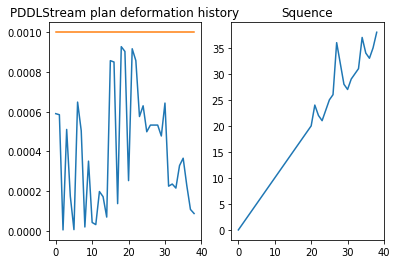

In [126]:
import matplotlib.pyplot as plt
from coop_assembly.planning.stiffness import TRANS_TOL

plt.figure(1)
plt.subplot(121)
plt.plot([t[1] for t in translations])
plt.plot([TRANS_TOL for _ in translations])
plt.title('PDDLStream plan deformation history')

plt.subplot(122)
plt.plot(element_sequence)
plt.title('Squence')

### Progression search

In [134]:
from coop_assembly.planning.stiffness import plan_stiffness
from coop_assembly.planning.validator import compute_plan_deformation

# progression search
progression_sequence = plan_stiffness(bar_struct, all_elements, trans_tol=trans_tol, stiffness=True, heuristic='z', max_time=pp.INF, 
    max_backtrack=0, verbose=False)

translations = compute_plan_deformation(bar_struct, progression_sequence)

Failed to find stiffness plan under tol 0.0005! Elements: 39, Min remaining 23, Time: 2.699sec


Text(0.5, 1.0, 'sequence')

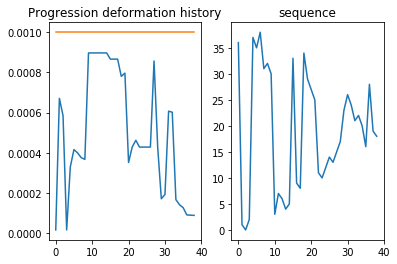

In [105]:
import matplotlib.pyplot as plt
from coop_assembly.planning.stiffness import TRANS_TOL

plt.figure(1)
plt.subplot(121)
plt.plot([t[1] for t in translations])
plt.plot([TRANS_TOL for _ in translations])
plt.title('Progression deformation history')

plt.subplot(122)
plt.plot(progression_sequence)
plt.title('sequence')